# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import ETCI2021floodsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

In [ ]:
#this dataset also contains water body labels that can be used

Total number of patches: 33405


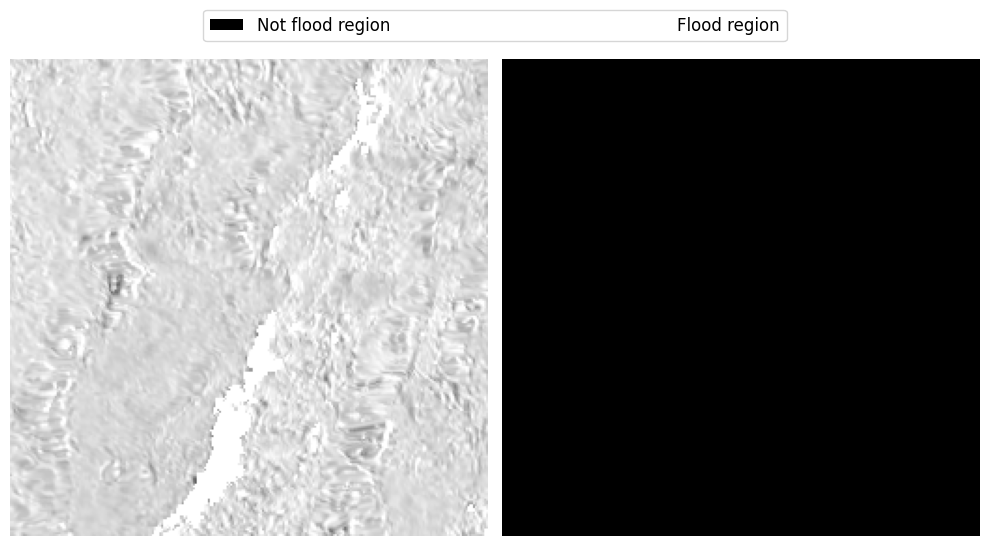

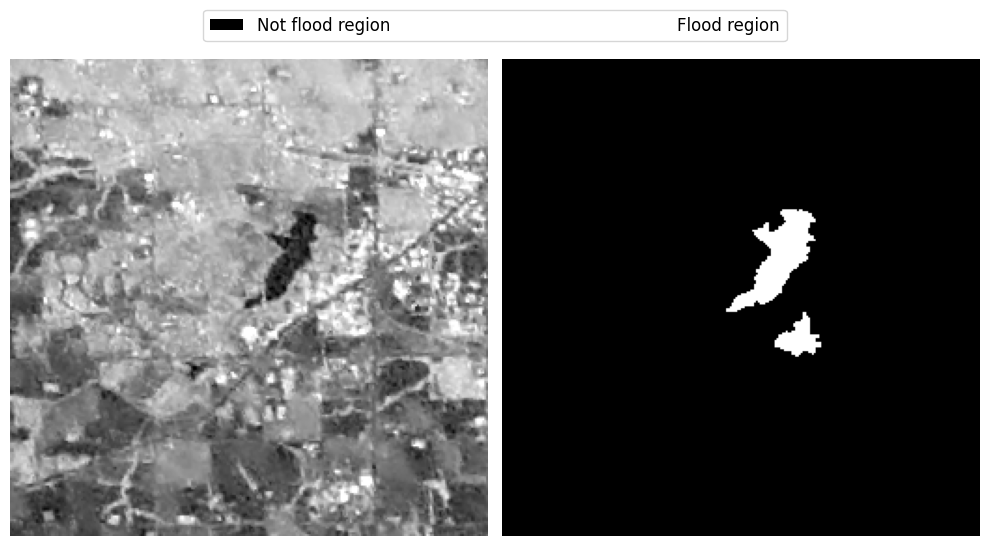

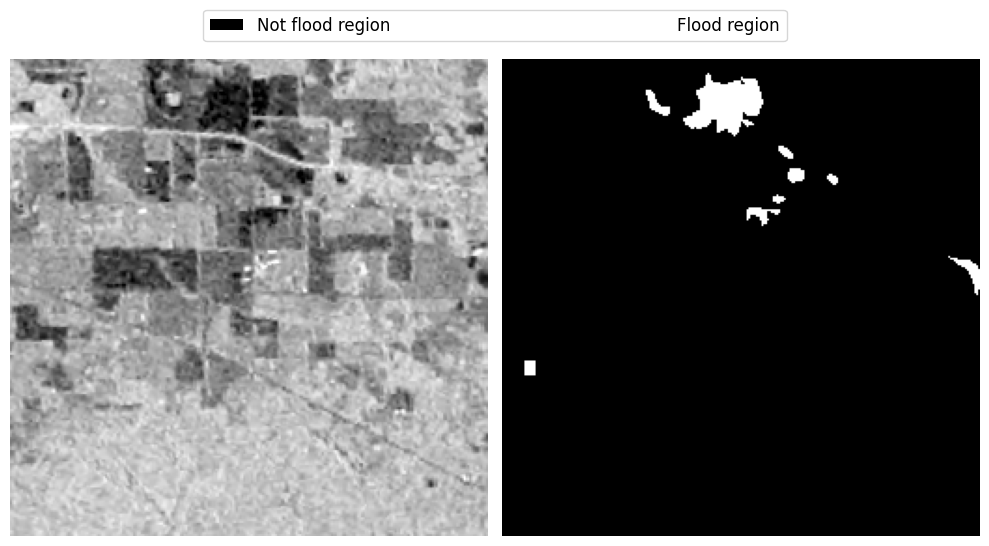

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ETCI_2021_floods/train"
}
dataset = ETCI2021floodsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(112);

In [4]:
dataset.data_distribution_table()

,Number of pixels
Not flood region,2.150474e+09
Flood region,3.875564e+07


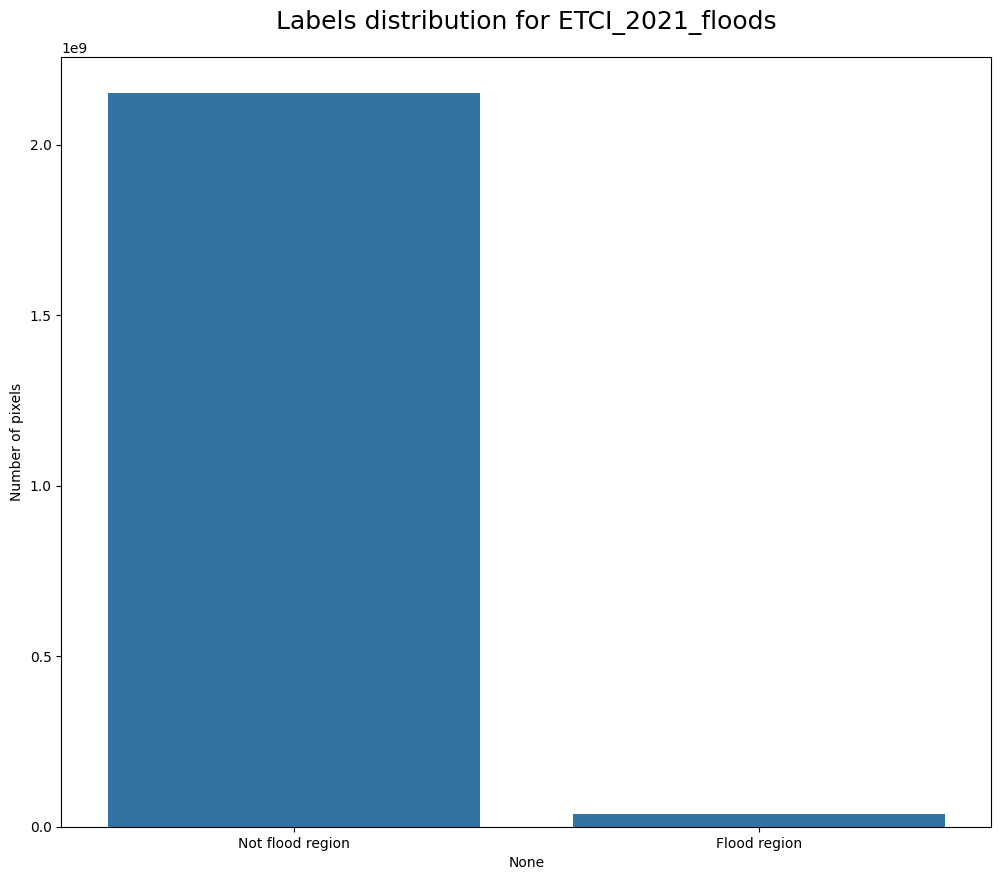

In [5]:
dataset.data_distribution_barchart();

## Load training data

In [3]:
train_dataset_config = {
    "batch_size": 15,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/ETCI_2021_floods/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = ETCI2021floodsDataset(train_dataset_config)
len(train_dataset)

33405

## Create the model 

In [4]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/ETCI_2021_floods"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [5]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-07 09:36:12,152 INFO Starting training.
training: 100%|██████████| 2227/2227 [47:31<00:00,  1.28s/it]
2025-03-07 10:23:43,563 INFO epoch: 1, time: 2851, loss:  0.05907
testing on train set: 100%|██████████| 2227/2227 [47:41<00:00,  1.28s/it] 
2025-03-07 11:11:26,724 INFO IOU:0.9839130738168981, IOU mean:0.775155391417885, IOU per Class:[0.99178138 0.5585294 ]
training: 100%|██████████| 2227/2227 [47:53<00:00,  1.29s/it]
2025-03-07 11:59:20,198 INFO epoch: 2, time: 2874, loss:  0.01042
testing on train set: 100%|██████████| 2227/2227 [47:45<00:00,  1.29s/it] 
2025-03-07 12:47:05,336 INFO IOU:0.9842219797014572, IOU mean:0.7813061772489145, IOU per Class:[0.99195847 0.57065388]
training: 100%|██████████| 2227/2227 [47:50<00:00,  1.29s/it]
2025-03-07 13:34:55,382 INFO epoch: 3, time: 2870, loss:  0.00932
testing on train set: 100%|██████████| 2227/2227 [47:39<00:00,  1.28s/it] 
2025-03-07 14:22:34,810 INFO IOU:0.9847183323969187, IOU mean:0.7882317597974429, IOU per Class:[0.99221

## Predictions

2025-03-10 09:37:34,275 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ETCI_2021_floods/checkpoint.pth.tar
2025-03-10 09:37:34,826 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ETCI_2021_floods/checkpoint.pth.tar at epoch 6


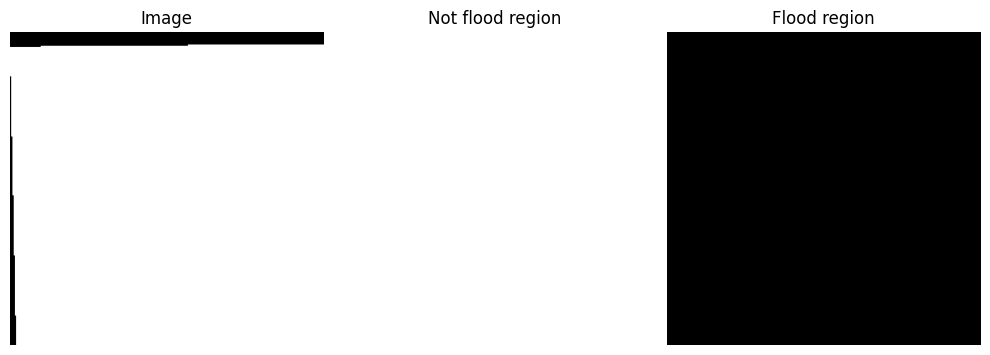

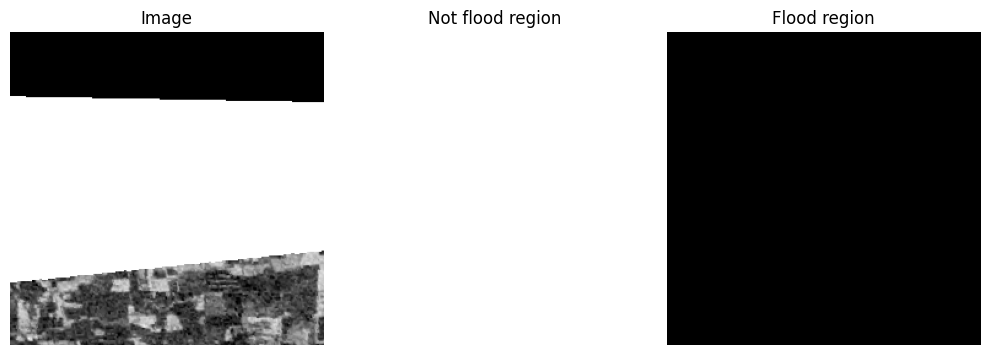

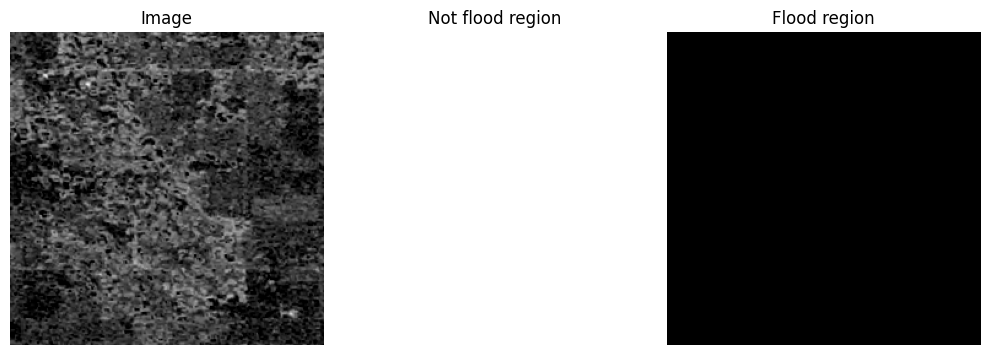

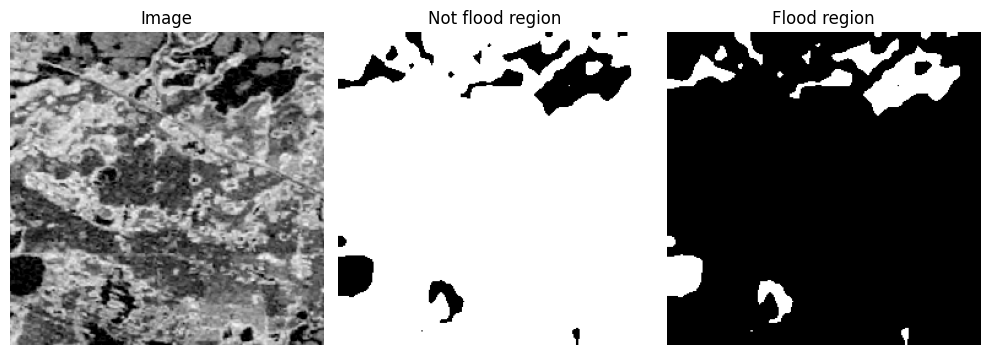

In [5]:
model_path = "/home/dragik/data/FAIR_EO/ETCI_2021_floods/checkpoint.pth.tar"
labels = ["Not flood region","Flood region"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/ETCI_2021_floods/test/images_vh/redrivernorth_20190104t002247_x-0_y-0_vh.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ETCI_2021_floods/test/images_vh/redrivernorth_20190104t002247_x-0_y-34_vh.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ETCI_2021_floods/test/images_vh/redrivernorth_20190209t002246_x-4_y-15_vh.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ETCI_2021_floods/test/images_vh/redrivernorth_20190422t002247_x-8_y-9_vh.png')
fig = model.predict_masks(image, labels, transform)